<a href="https://colab.research.google.com/github/UnnimayaVAshok/my_projects/blob/main/machine_failure.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv("machine_failure_dataset.csv")
df = pd.DataFrame(data)
df

,Temperature,Vibration,Power_Usage,Humidity,Machine_Type,Failure_Risk
0,74.967142,56.996777,8.649643,20.460962,Mill,1
1,68.617357,54.623168,9.710963,25.698075,Lathe,0
2,76.476885,50.298152,8.415160,27.931972,Drill,1
3,85.230299,46.765316,9.384077,39.438438,Lathe,1
4,67.658466,53.491117,6.212771,32.782766,Drill,1
...,...,...,...,...,...,...
995,67.188997,55.350751,10.154961,30.142288,Lathe,1
996,87.976865,49.867394,10.515505,19.610941,Drill,0
997,76.408429,45.590627,7.516479,28.398511,Mill,0
998,64.288210,49.184665,10.668353,38.216891,Mill,1


In [ ]:
df.head()

,Temperature,Vibration,Power_Usage,Humidity,Machine_Type,Failure_Risk
0,74.967142,56.996777,8.649643,20.460962,Mill,1
1,68.617357,54.623168,9.710963,25.698075,Lathe,0
2,76.476885,50.298152,8.415160,27.931972,Drill,1
3,85.230299,46.765316,9.384077,39.438438,Lathe,1
4,67.658466,53.491117,6.212771,32.782766,Drill,1


In [ ]:
df.tail()

,Temperature,Vibration,Power_Usage,Humidity,Machine_Type,Failure_Risk
995,67.188997,55.350751,10.154961,30.142288,Lathe,1
996,87.976865,49.867394,10.515505,19.610941,Drill,0
997,76.408429,45.590627,7.516479,28.398511,Mill,0
998,64.288210,49.184665,10.668353,38.216891,Mill,1
999,75.725828,46.275487,9.689482,31.803239,Mill,0


In [ ]:
df.shape

(1000, 6)

In [ ]:
df.columns

Index(['Temperature', 'Vibration', 'Power_Usage', 'Humidity', 'Machine_Type',
       'Failure_Risk'],
      dtype='object')

In [ ]:
df.describe()

,Temperature,Vibration,Power_Usage,Humidity,Failure_Risk
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,70.193321,50.354181,10.011668,29.906404,0.300000
std,9.792159,4.987272,1.966909,5.135663,0.458487
min,37.587327,35.298057,3.960976,15.352757,0.000000
25%,63.524097,46.968792,8.704001,26.312898,0.000000
50%,70.253006,50.315386,9.999498,30.000923,0.000000
75%,76.479439,53.644411,11.321831,33.334727,1.000000
max,108.527315,65.965538,17.852475,46.215465,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Temperature   1000 non-null   float64
 1   Vibration     1000 non-null   float64
 2   Power_Usage   1000 non-null   float64
 3   Humidity      1000 non-null   float64
 4   Machine_Type  1000 non-null   object 
 5   Failure_Risk  1000 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 47.0+ KB


In [ ]:
df.isna().sum()

,0
Temperature,0
Vibration,0
Power_Usage,0
Humidity,0
Machine_Type,0
Failure_Risk,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df_1 = df.drop("Machine_Type",axis = 1)
df_1.corr()

,Temperature,Vibration,Power_Usage,Humidity,Failure_Risk
Temperature,1.000000,-0.040400,0.022129,-0.013321,0.029938
Vibration,-0.040400,1.000000,-0.011199,-0.054698,-0.001727
Power_Usage,0.022129,-0.011199,1.000000,0.021586,0.020971
Humidity,-0.013321,-0.054698,0.021586,1.000000,-0.018007
Failure_Risk,0.029938,-0.001727,0.020971,-0.018007,1.000000


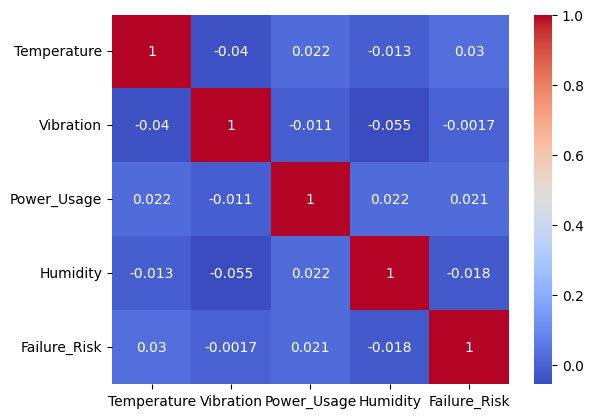

In [ ]:
sns.heatmap(df_1.corr(),annot = True,cmap="coolwarm")
plt.show()

In [ ]:
df["Failure_Risk"].value_counts()

,count
Failure_Risk,
0,700
1,300


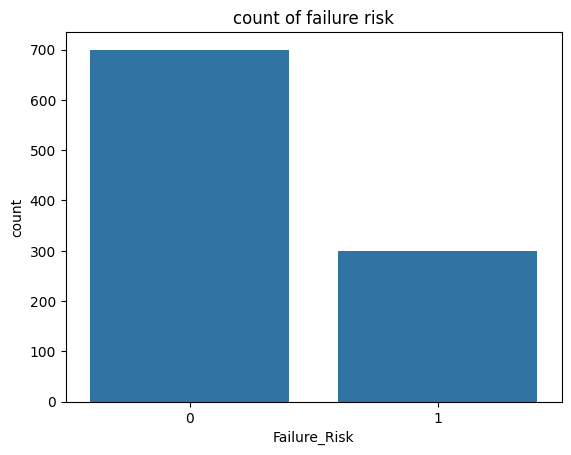

In [ ]:
sns.countplot(data = df,x = "Failure_Risk")
plt.title("count of failure risk")
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["Machine_Type"] = le.fit_transform(df["Machine_Type"])

In [ ]:
X = df.drop("Failure_Risk",axis = 1)
y = df["Failure_Risk"]
X,y

(     Temperature  Vibration  Power_Usage   Humidity  Machine_Type
 0      74.967142  56.996777     8.649643  20.460962             2
 1      68.617357  54.623168     9.710963  25.698075             1
 2      76.476885  50.298152     8.415160  27.931972             0
 3      85.230299  46.765316     9.384077  39.438438             1
 4      67.658466  53.491117     6.212771  32.782766             0
 ..           ...        ...          ...        ...           ...
 995    67.188997  55.350751    10.154961  30.142288             1
 996    87.976865  49.867394    10.515505  19.610941             0
 997    76.408429  45.590627     7.516479  28.398511             2
 998    64.288210  49.184665    10.668353  38.216891             2
 999    75.725828  46.275487     9.689482  31.803239             2
 
 [1000 rows x 5 columns],
 0      1
 1      0
 2      1
 3      1
 4      1
       ..
 995    1
 996    0
 997    0
 998    1
 999    0
 Name: Failure_Risk, Length: 1000, dtype: int64)

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.3,random_state = 42,stratify = y)

In [ ]:
"""from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)"""

'from sklearn.preprocessing import StandardScaler\n\nscaler = StandardScaler()\nX_train = scaler.fit_transform(X_train)\nX_test = scaler.transform(X_test)'

In [ ]:
"""from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred"""

'from sklearn.neighbors import KNeighborsClassifier\n\nmodel = KNeighborsClassifier()\nmodel.fit(X_train,y_train)\ny_pred = model.predict(X_test)\ny_pred'

0.6533333333333333
0.13333333333333333
[[184  26]
 [ 78  12]]
              precision    recall  f1-score   support

           0       0.70      0.88      0.78       210
           1       0.32      0.13      0.19        90

    accuracy                           0.65       300
   macro avg       0.51      0.50      0.48       300
weighted avg       0.59      0.65      0.60       300

In [ ]:
from sklearn.naive_bayes import BernoulliNB

model = BernoulliNB()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

0.7
[[210   0]
 [ 90   0]]
              precision    recall  f1-score   support

           0       0.70      1.00      0.82       210
           1       0.00      0.00      0.00        90

    accuracy                           0.70       300
   macro avg       0.35      0.50      0.41       300
weighted avg       0.49      0.70      0.58       300

In [ ]:
"""from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(criterion = "entropy")
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred"""

'from sklearn.tree import DecisionTreeClassifier\n\nmodel = DecisionTreeClassifier(criterion = "entropy")\nmodel.fit(X_train,y_train)\ny_pred = model.predict(X_test)\ny_pred'

0.63
0.36666666666666664
[[156  54]
 [ 57  33]]
              precision    recall  f1-score   support

           0       0.73      0.74      0.74       210
           1       0.38      0.37      0.37        90

    accuracy                           0.63       300
   macro avg       0.56      0.55      0.56       300
weighted avg       0.63      0.63      0.63       300

In [ ]:
"""from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state = 42)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred"""

'from sklearn.ensemble import RandomForestClassifier\n\nmodel = RandomForestClassifier(random_state = 42)\nmodel.fit(X_train,y_train)\ny_pred = model.predict(X_test)\ny_pred'

0.6733333333333333
0.06666666666666667
[[196  14]
 [ 84   6]]
              precision    recall  f1-score   support

           0       0.70      0.93      0.80       210
           1       0.30      0.07      0.11        90

    accuracy                           0.67       300
   macro avg       0.50      0.50      0.45       300
weighted avg       0.58      0.67      0.59       300


In [ ]:
from sklearn.metrics import accuracy_score,recall_score,confusion_matrix,classification_report

print(accuracy_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.7
[[210   0]
 [ 90   0]]
              precision    recall  f1-score   support

           0       0.70      1.00      0.82       210
           1       0.00      0.00      0.00        90

    accuracy                           0.70       300
   macro avg       0.35      0.50      0.41       300
weighted avg       0.49      0.70      0.58       300



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
